
# Análise de Churn — Telecomunicações

## 1. Apresentação do projeto

Projeto de análise de dados desenvolvido com PostgreSQL, SQL e Python, utilizando o conjunto de dados Telco Customer Churn, disponibilizado pela IBM.

O objetivo é investigar os fatores associados ao cancelamento de serviços de telecomunicações, identificar padrões no comportamento dos clientes e apresentar oportunidades de melhoria na retenção.

## 2. Objetivos da análise

- Identificar a taxa geral de cancelamento.
- Investigar o churn por tipo de contrato.
- Analisar o comportamento dos clientes conforme tempo de relacionamento.
- Avaliar a relação entre serviços contratados e cancelamentos.
- Investigar diferenças por forma de pagamento e perfil dos clientes.
- Apresentar os resultados por meio de visualizações.

## 3. Ferramentas utilizadas

- PostgreSQL
- SQL
- Python
- Pandas
- Matplotlib
- Google Colab



## 4. Importação das bibliotecas e carregamento dos dados

Nesta etapa, são importadas as bibliotecas Pandas e Matplotlib, utilizadas para manipulação, exploração e visualização dos dados.

Em seguida, é realizado o carregamento do arquivo CSV exportado do PostgreSQL para um DataFrame do Pandas.

O conjunto de dados contém 7.043 registros e 21 colunas, representando informações sobre os clientes, serviços contratados, cobranças e cancelamentos.


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

print("Projeto Telco Customer Churn iniciado!")

print("Versão do Pandas:", pd.__version__)

Projeto Telco Customer Churn iniciado!
Versão do Pandas: 2.2.3


In [14]:
from google.colab import files

arquivo = files.upload()

df = pd.read_csv("clientes_churn.csv")

print("Dados carregados com sucesso!")
print("Dimensões do conjunto de dados:", df.shape)

df.head()

Saving clientes_churn.csv to clientes_churn (1).csv
Dados carregados com sucesso!
Dimensões do conjunto de dados: (7043, 21)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



## 5. Exploração inicial e qualidade dos dados

Nesta etapa, foi realizada uma exploração inicial do conjunto de dados para verificar sua estrutura, os tipos das variáveis, a presença de valores ausentes e as principais estatísticas descritivas.

A base possui 7.043 registros e 21 colunas.

### Qualidade dos dados

- Os identificadores dos clientes foram preservados.
- As variáveis numéricas foram reconhecidas corretamente pelo Pandas.
- Foram identificados 11 valores ausentes na coluna `totalcharges`.
- Os 11 registros correspondem a clientes com tempo de relacionamento igual a zero (`tenure = 0`).

Os registros com valores ausentes foram mantidos, evitando a exclusão de clientes válidos da análise.


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   object 
 4   dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   object 
 7   multiplelines     7043 non-null   object 
 8   internetservice   7043 non-null   object 
 9   onlinesecurity    7043 non-null   object 
 10  onlinebackup      7043 non-null   object 
 11  deviceprotection  7043 non-null   object 
 12  techsupport       7043 non-null   object 
 13  streamingtv       7043 non-null   object 
 14  streamingmovies   7043 non-null   object 
 15  contract          7043 non-null   object 
 16  paperlessbilling  7043 non-null   object 


In [16]:
df.describe().round(2)

,seniorcitizen,tenure,monthlycharges,totalcharges
count,7043.00,7043.00,7043.00,7032.00
mean,0.16,32.37,64.76,2283.30
std,0.37,24.56,30.09,2266.77
min,0.00,0.00,18.25,18.80
25%,0.00,9.00,35.50,401.45
50%,0.00,29.00,70.35,1397.48
75%,0.00,55.00,89.85,3794.74
max,1.00,72.00,118.75,8684.80



## 6. Análise Exploratória e Visualização dos Dados

Nesta etapa, são realizadas análises exploratórias para identificar padrões de cancelamento e características dos clientes associadas ao churn.

Foram utilizadas operações de agrupamento e cálculo de indicadores com Pandas, além da biblioteca Matplotlib para construção dos gráficos.

As análises investigam diferentes dimensões:

- Distribuição geral de cancelamentos.
- Tipo de contrato.
- Forma de pagamento.
- Tempo de relacionamento.
- Serviço de internet.
- Cobrança mensal.
- Serviços adicionais contratados.



### 6.1. Distribuição de clientes por status

A análise da distribuição dos clientes permite identificar a proporção de clientes que permaneceram na empresa e daqueles que cancelaram os serviços.

**Resultados:**

- Clientes ativos: 5.174 (73,46%).
- Clientes cancelados: 1.869 (26,54%).

**Interpretação:**

Aproximadamente 1 em cada 4 clientes cancelou os serviços. Esse resultado demonstra a relevância do churn como indicador para o negócio e justifica investigar os fatores associados à perda de clientes.


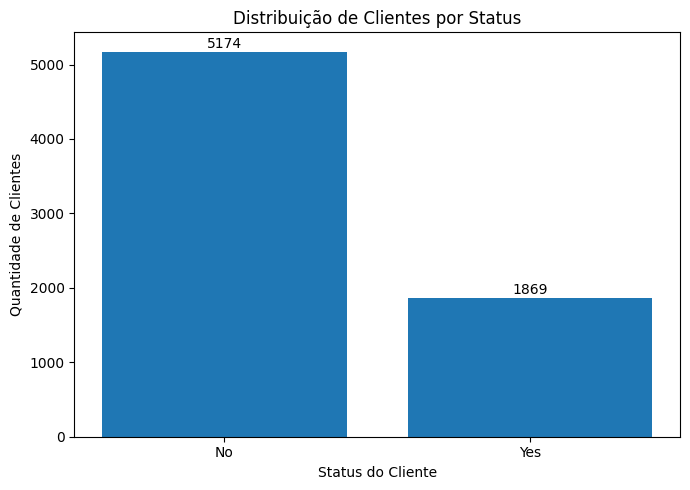

In [17]:
churn_counts = df["churn"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title("Distribuição de Clientes por Status")
plt.xlabel("Status do Cliente")
plt.ylabel("Quantidade de Clientes")

for i, valor in enumerate(churn_counts.values):
    plt.text(i, valor + 50, str(valor), ha="center")

plt.tight_layout()
plt.show()


### 6.2. Taxa de cancelamento por tipo de contrato

Esta análise investiga a relação entre a modalidade de contrato e o cancelamento dos serviços.

**Resultados:**

- Contrato mensal: 42,71% de churn.
- Contrato anual: 11,27% de churn.
- Contrato bienal: 2,83% de churn.

**Interpretação:**

Clientes com contratos mensais apresentam uma taxa de cancelamento significativamente superior à dos clientes com contratos de maior duração.

A taxa de churn dos contratos mensais é aproximadamente 15 vezes maior que a dos contratos bienais.

**Oportunidade de negócio:**

Investigar estratégias de retenção e incentivos para estimular a adesão a contratos de maior duração.


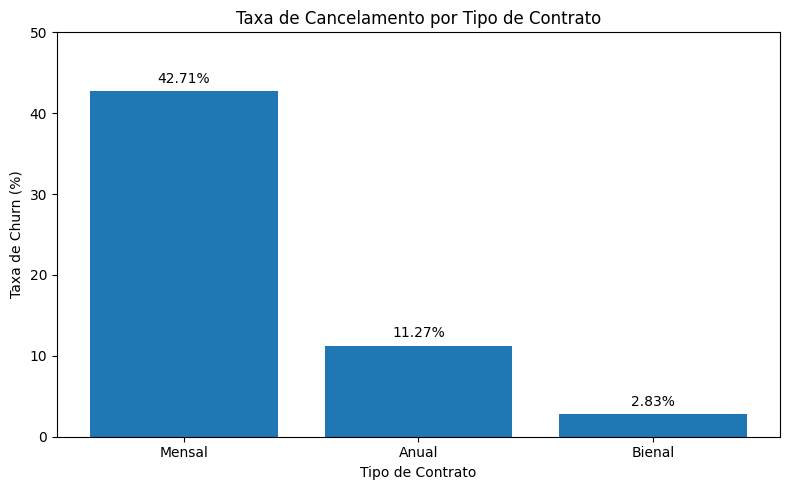

In [18]:
churn_contrato = (
    df.groupby("contract")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

nomes_contratos = {
    "Month-to-month": "Mensal",
    "One year": "Anual",
    "Two year": "Bienal"
}

churn_contrato.index = churn_contrato.index.map(nomes_contratos)

plt.figure(figsize=(8, 5))

plt.bar(churn_contrato.index, churn_contrato.values)

plt.title("Taxa de Cancelamento por Tipo de Contrato")
plt.xlabel("Tipo de Contrato")
plt.ylabel("Taxa de Churn (%)")

for i, valor in enumerate(churn_contrato.values):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()


### 6.3. Taxa de cancelamento por forma de pagamento

Esta análise investiga se a forma de pagamento utilizada pelos clientes apresenta associação com o cancelamento dos serviços.

**Resultados:**

- Cheque eletrônico: 45,29%.
- Cheque pelo correio: 19,11%.
- Transferência automática: 16,71%.
- Cartão de crédito automático: 15,24%.

**Interpretação:**

Clientes que utilizam cheque eletrônico apresentam a maior taxa de cancelamento entre as modalidades analisadas.

As formas de pagamento automáticas apresentam taxas menores de churn.

**Oportunidade de negócio:**

Investigar a experiência dos clientes que utilizam cheque eletrônico e avaliar alternativas que facilitem a adesão a métodos de pagamento automáticos.


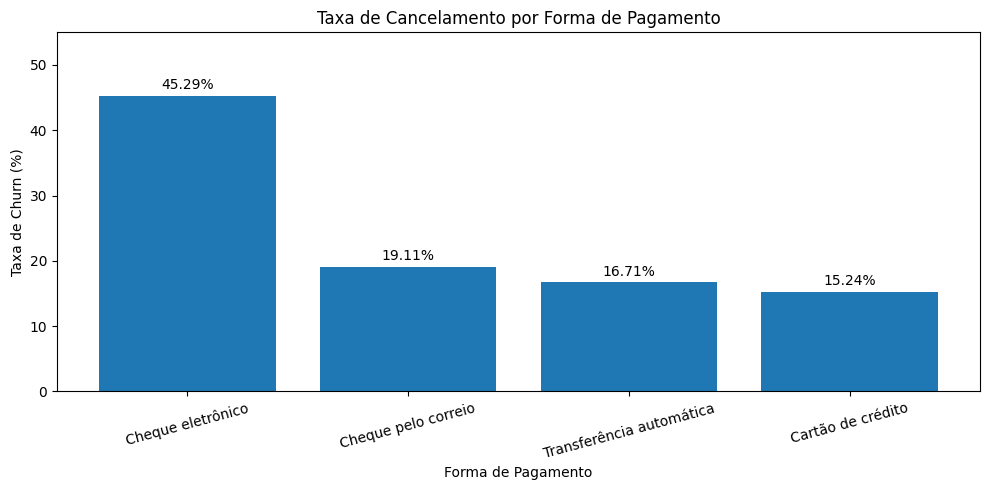

In [19]:
churn_pagamento = (
    df.groupby("paymentmethod")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

nomes_pagamento = {
    "Electronic check": "Cheque eletrônico",
    "Mailed check": "Cheque pelo correio",
    "Bank transfer (automatic)": "Transferência automática",
    "Credit card (automatic)": "Cartão de crédito"
}

churn_pagamento.index = churn_pagamento.index.map(nomes_pagamento)

plt.figure(figsize=(10, 5))

plt.bar(churn_pagamento.index, churn_pagamento.values)

plt.title("Taxa de Cancelamento por Forma de Pagamento")
plt.xlabel("Forma de Pagamento")
plt.ylabel("Taxa de Churn (%)")
plt.xticks(rotation=15)

for i, valor in enumerate(churn_pagamento.values):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.ylim(0, 55)
plt.tight_layout()
plt.show()


### 6.4. Taxa de cancelamento por tempo de relacionamento

Esta análise investiga como o tempo de relacionamento dos clientes com a empresa está associado ao cancelamento dos serviços.

**Resultados:**

- Até 12 meses: 47,44%.
- De 13 a 36 meses: 25,54%.
- Mais de 36 meses: 11,93%.

**Interpretação:**

Clientes com menor tempo de relacionamento apresentam taxas de cancelamento mais elevadas.

A taxa de churn diminui conforme aumenta o tempo de permanência na empresa. Esse resultado destaca a importância de acompanhar os clientes durante os primeiros meses de relacionamento.

**Oportunidade de negócio:**

Desenvolver estratégias de integração, acompanhamento e relacionamento para clientes recém-contratados, buscando melhorar sua experiência inicial.


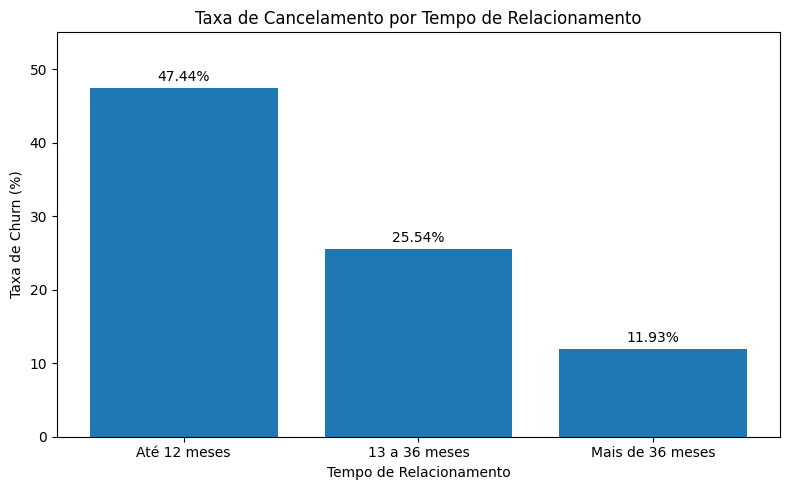

In [20]:
df["grupo_tenure"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 36, 72],
    labels=["Até 12 meses", "13 a 36 meses", "Mais de 36 meses"]
)

churn_tenure = (
    df.groupby("grupo_tenure", observed=False)["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(8, 5))

plt.bar(churn_tenure.index, churn_tenure.values)

plt.title("Taxa de Cancelamento por Tempo de Relacionamento")
plt.xlabel("Tempo de Relacionamento")
plt.ylabel("Taxa de Churn (%)")

for i, valor in enumerate(churn_tenure.values):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.ylim(0, 55)
plt.tight_layout()
plt.show()


### 6.5. Taxa de cancelamento por serviço de internet

Esta análise investiga a relação entre o tipo de serviço de internet contratado e o cancelamento dos clientes.

**Resultados:**

- Fibra óptica: 41,89%.
- DSL: 18,96%.
- Sem serviço de internet: 7,40%.

**Interpretação:**

Clientes que utilizam fibra óptica apresentam a maior taxa de cancelamento entre os grupos analisados.

Esse resultado merece atenção, pois pode indicar oportunidades para investigar a qualidade do serviço, os preços praticados e a satisfação dos clientes.

**Oportunidade de negócio:**

Investigar as razões do maior cancelamento entre clientes de fibra óptica, buscando identificar possíveis problemas relacionados à experiência e à percepção de valor do serviço.


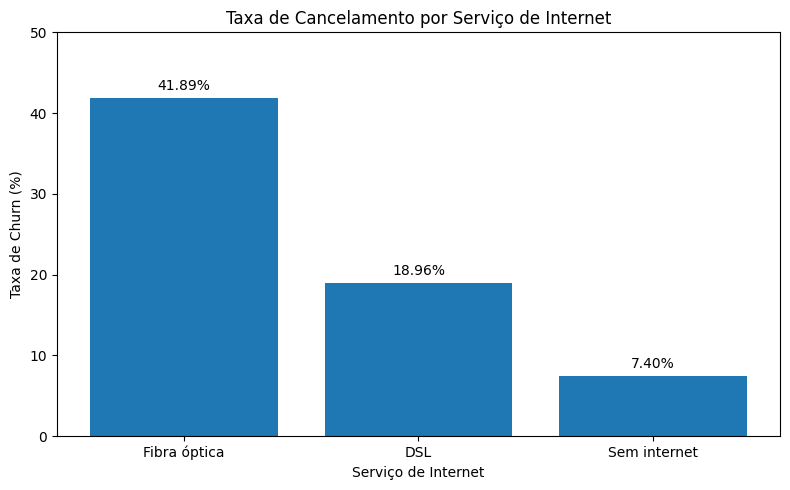

In [21]:
churn_internet = (
    df.groupby("internetservice")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

nomes_internet = {
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "No": "Sem internet"
}

churn_internet.index = churn_internet.index.map(nomes_internet)

plt.figure(figsize=(8, 5))

plt.bar(churn_internet.index, churn_internet.values)

plt.title("Taxa de Cancelamento por Serviço de Internet")
plt.xlabel("Serviço de Internet")
plt.ylabel("Taxa de Churn (%)")

for i, valor in enumerate(churn_internet.values):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()


### 6.6. Cobrança mensal média por status do cliente

Esta análise compara os valores médios de cobrança mensal entre clientes ativos e clientes que cancelaram os serviços.

**Resultados:**

- Clientes ativos: R$ 61,27.
- Clientes cancelados: R$ 74,44.

**Interpretação:**

Clientes que cancelaram os serviços apresentavam uma cobrança mensal média superior à dos clientes que permaneceram na empresa.

A diferença de R$ 13,17 sugere uma possível associação entre o valor mensal pago e o cancelamento.

**Oportunidade de negócio:**

Investigar a percepção de custo-benefício dos clientes, avaliando se os valores cobrados estão adequados aos serviços oferecidos.


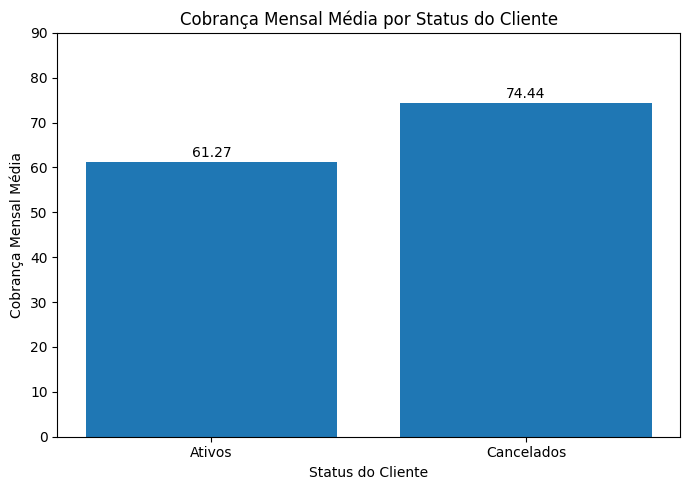

In [22]:
media_cobranca = df.groupby("churn")["monthlycharges"].mean()

nomes_status = {
    "No": "Ativos",
    "Yes": "Cancelados"
}

media_cobranca.index = media_cobranca.index.map(nomes_status)

plt.figure(figsize=(7, 5))

plt.bar(media_cobranca.index, media_cobranca.values)

plt.title("Cobrança Mensal Média por Status do Cliente")
plt.xlabel("Status do Cliente")
plt.ylabel("Cobrança Mensal Média")

for i, valor in enumerate(media_cobranca.values):
    plt.text(i, valor + 1, f"{valor:.2f}", ha="center")

plt.ylim(0, 90)
plt.tight_layout()
plt.show()


### 6.7. Taxa de cancelamento por suporte técnico

Esta análise compara as taxas de cancelamento entre clientes que possuem e não possuem o serviço de suporte técnico. Foram considerados apenas clientes com serviço de internet.

**Resultados:**

- Sem suporte técnico: 41,64%.
- Com suporte técnico: 15,17%.

**Interpretação:**

Clientes sem suporte técnico apresentam uma taxa de cancelamento consideravelmente maior.

A diferença observada sugere uma associação entre a disponibilidade desse serviço e a retenção de clientes.

**Oportunidade de negócio:**

Investigar a qualidade e a disponibilidade do suporte técnico, além de avaliar estratégias para ampliar a adesão ao serviço.


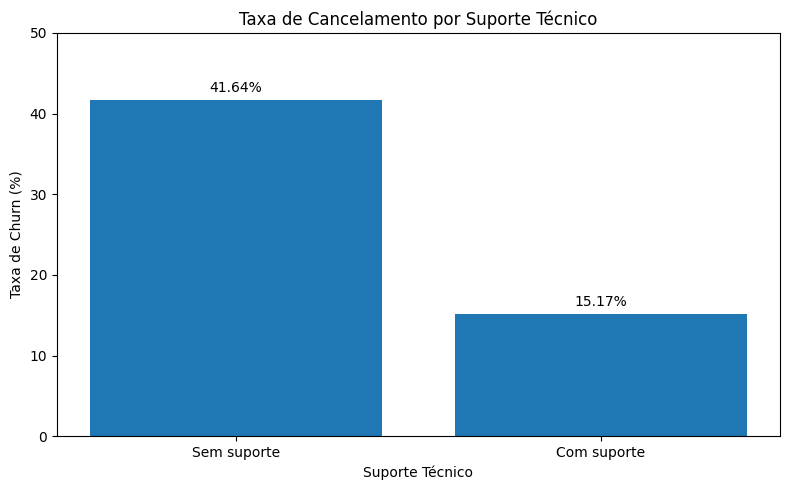

In [23]:
df_internet = df[df["internetservice"] != "No"]

churn_suporte = (
    df_internet.groupby("techsupport")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

nomes_suporte = {
    "No": "Sem suporte",
    "Yes": "Com suporte"
}

churn_suporte.index = churn_suporte.index.map(nomes_suporte)

plt.figure(figsize=(8, 5))

plt.bar(churn_suporte.index, churn_suporte.values)

plt.title("Taxa de Cancelamento por Suporte Técnico")
plt.xlabel("Suporte Técnico")
plt.ylabel("Taxa de Churn (%)")

for i, valor in enumerate(churn_suporte.values):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()


### 6.8. Taxa de cancelamento por segurança online

Esta análise compara as taxas de cancelamento entre clientes que possuem e não possuem o serviço de segurança online. Foram considerados apenas clientes com serviço de internet.

**Resultados:**

- Sem segurança online: 41,77%.
- Com segurança online: 14,61%.

**Interpretação:**

Clientes que não possuem segurança online apresentam uma taxa de cancelamento significativamente maior.

A diferença observada sugere uma associação entre a contratação desse serviço e a retenção de clientes.

**Oportunidade de negócio:**

Investigar a percepção de valor dos serviços adicionais e avaliar estratégias para ampliar a adesão à segurança online.


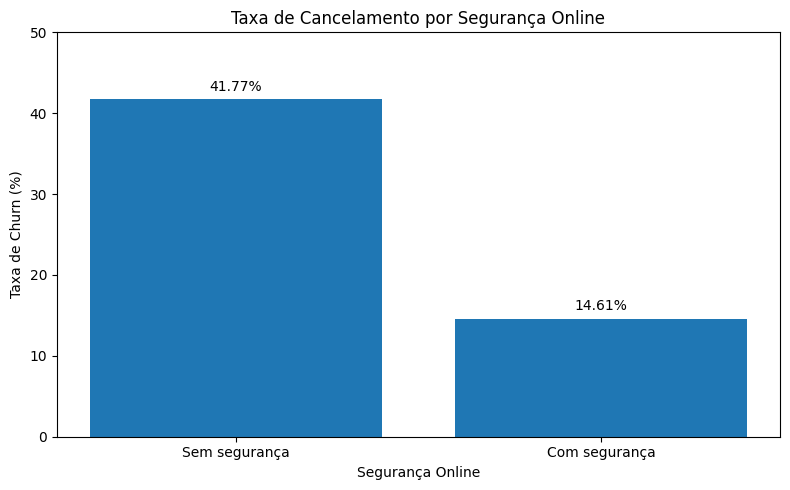

In [24]:
df_internet = df[df["internetservice"] != "No"]

churn_seguranca = (
    df_internet.groupby("onlinesecurity")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

nomes_seguranca = {
    "No": "Sem segurança",
    "Yes": "Com segurança"
}

churn_seguranca.index = churn_seguranca.index.map(nomes_seguranca)

plt.figure(figsize=(8, 5))

plt.bar(churn_seguranca.index, churn_seguranca.values)

plt.title("Taxa de Cancelamento por Segurança Online")
plt.xlabel("Segurança Online")
plt.ylabel("Taxa de Churn (%)")

for i, valor in enumerate(churn_seguranca.values):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()


## 7. Principais Descobertas

A análise dos 7.043 clientes permitiu identificar padrões importantes relacionados ao cancelamento dos serviços.

### 7.1. Contratos de curta duração apresentam maior churn

Clientes com contratos mensais apresentam uma taxa de cancelamento de 42,71%, enquanto clientes com contratos bienais apresentam apenas 2,83%.

### 7.2. Clientes recentes apresentam maior risco de cancelamento

A taxa de churn entre clientes com até 12 meses de relacionamento é de 47,44%, diminuindo para 11,93% entre aqueles com mais de 36 meses.

### 7.3. Forma de pagamento apresenta diferenças relevantes

O cheque eletrônico apresenta a maior taxa de cancelamento entre as modalidades analisadas, com 45,29%.

### 7.4. Serviços adicionais estão associados à retenção

Clientes sem suporte técnico apresentam churn de 41,64%, contra 15,17% daqueles que possuem o serviço.

Na segurança online, a diferença também é expressiva: 41,77% sem o serviço e 14,61% com o serviço.

### 7.5. Clientes de fibra óptica apresentam maior cancelamento

A taxa de churn entre clientes de fibra óptica é de 41,89%, superior à observada entre clientes DSL (18,96%).

### 7.6. Clientes que cancelaram apresentam maior cobrança mensal média

A cobrança mensal média dos clientes cancelados é de R$ 74,44, enquanto a dos clientes ativos é de R$ 61,27.



## 8. Conclusão e Recomendações de Negócio

A análise identificou uma taxa geral de cancelamento de 26,54% entre os clientes da empresa.

Os resultados apontam maior concentração de cancelamentos entre clientes com contratos mensais, menor tempo de relacionamento, pagamento por cheque eletrônico e ausência de determinados serviços adicionais.

Também foi observada uma cobrança mensal média mais elevada entre os clientes que cancelaram seus serviços.

Com base nesses resultados, algumas iniciativas podem ser consideradas:

- **Fortalecer a retenção nos primeiros meses:** desenvolver ações de acompanhamento e relacionamento para clientes recém-contratados.
- **Incentivar contratos de maior duração:** avaliar condições comerciais e benefícios que estimulem a permanência dos clientes.
- **Investigar a experiência dos clientes de fibra óptica:** analisar qualidade, estabilidade e percepção de custo-benefício do serviço.
- **Avaliar os serviços de suporte e segurança:** investigar como esses serviços podem contribuir para a satisfação e retenção.
- **Analisar a experiência de pagamento:** investigar possíveis dificuldades ou insatisfações relacionadas ao cheque eletrônico.
- **Avaliar a percepção de preço:** investigar se os valores cobrados estão adequados aos serviços oferecidos.

As recomendações representam oportunidades de investigação e ação. Sua efetividade deverá ser avaliada por meio de iniciativas de retenção e acompanhamento dos indicadores ao longo do tempo.

### Considerações finais

O projeto demonstrou como a integração entre PostgreSQL, SQL e Python permite explorar grandes conjuntos de dados, identificar padrões de comportamento e transformar resultados analíticos em informações úteis para a tomada de decisões.

A análise reforça a importância do acompanhamento contínuo do churn como indicador estratégico para empresas que desejam melhorar a retenção e fortalecer o relacionamento com seus clientes.

## 9. Fonte dos Dados

Conjunto de dados Telco Customer Churn, disponibilizado pela IBM.

Fonte: [IBM Telco Customer Churn Dataset](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv)
